# Part 2 — The score is a force
Paper §2.2 (Eq. 5–6), §3.2, App. B.1, C.1, C.4. See [README.md](README.md).

Goals: (1) the Müller–Brown system and its Boltzmann samples, (2) Langevin dynamics reproduces the Boltzmann
distribution, independent of mass/friction, (3) score = force / kT, (4) conservative vs. non-conservative models.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent            # notebooks live one level below the project root
sys.path.insert(0, str(ROOT))
import numpy as np, torch, matplotlib.pyplot as plt
torch.set_default_dtype(torch.float64)      # float64: the FP estimator uses finite differences with sigma=1e-4
torch.set_num_threads(8)
from scoremd import sde, models, losses, sampling, simulate, metrics, potentials, plotting, experiments as ex
%matplotlib inline

## 1. The Müller–Brown potential (Eq. 34)

Text(0.5, 1.0, 'Mueller-Brown potential (clipped at 100)')

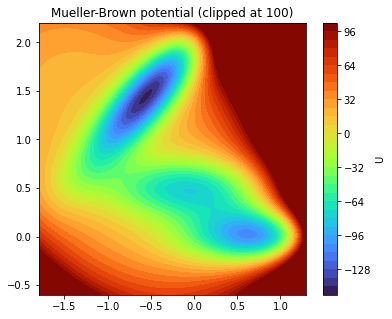

In [2]:
X, Y = np.meshgrid(np.linspace(-1.8, 1.3, 200), np.linspace(-0.6, 2.2, 200))
U = potentials.mueller_brown(torch.tensor(np.stack([X, Y], -1))).numpy()
plt.figure(figsize=(6, 5)); plt.contourf(X, Y, np.minimum(U, 100), 40, cmap='turbo'); plt.colorbar(label='U')
plt.title('Mueller-Brown potential (clipped at 100)')

## 2. Training data: Langevin MD at kT = 23 (App. C.4)
Generated once (~1 min) and cached in `results/mueller_brown_data.pt`.

fraction in the small right basin: 0.13691


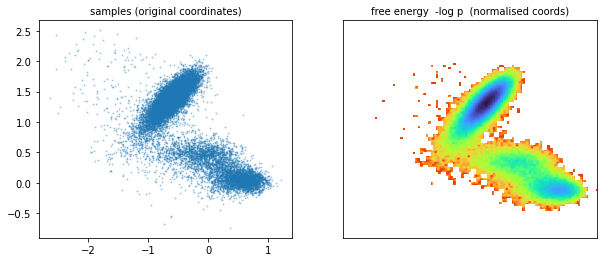

In [3]:
x, info = ex.load_system('mb')     # normalised coordinates
raw = x * info['scale'] + info['shift']
rng = metrics.hist_range(x)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plotting.scatter(ax[0], raw[:20000], title='samples (original coordinates)')
plotting.free_energy_hist(ax[1], x, rng, title='free energy  -log p  (normalised coords)')
print('fraction in the small right basin:', ex.mb_small_basin_fraction(x, info))

## 3. Score = force / kT (Eq. 6)
For the true Boltzmann density `p = exp(-U/kT)/Z`: `∇ log p = -∇U/kT`. In normalised coordinates
`x̃ = (x-μ)/σ` the chain rule gives `∇̃ log p = σ · F(x)/kT` — implemented in `ex.mb_true_force_normalised`.
Simulating Langevin dynamics with this force (kT = 1 in normalised units) must reproduce the data.

small basin  data: 0.13691  sim: 0.133
metrics true-force sim vs data: {'pmf': 2.250021410523641, 'js': 0.009735779858497703}


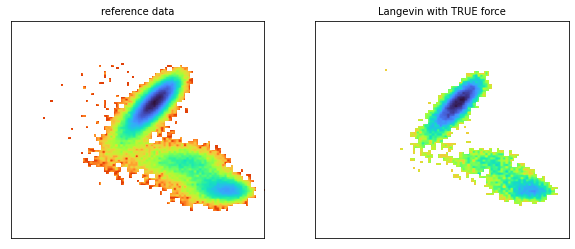

In [4]:
F_true = ex.mb_true_force_normalised(info)
sim_true, traj_true = ex.simulate_model(None, x, force=F_true, n_steps=10_000)
ref2 = x[torch.randperm(len(x))[:len(sim_true)]]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plotting.free_energy_hist(ax[0], x, rng, title='reference data')
plotting.free_energy_hist(ax[1], sim_true, rng, title='Langevin with TRUE force')
print('small basin  data:', ex.mb_small_basin_fraction(x, info), ' sim:', ex.mb_small_basin_fraction(sim_true, info))
print('metrics true-force sim vs data:', ex.compare(sim_true, x))

**Noise floor.** Even a perfect simulation has nonzero PMF/JS because of finite samples. Compare two independent
halves of the reference data: this is the "Reference" row of Table 10.

In [5]:
perm = torch.randperm(len(x)); half = len(x) // 2
print('reference vs reference:', ex.compare(x[perm[:half]], x[perm[half:]], n=len(sim_true)))

reference vs reference: {'pmf': 2.3037911346632534, 'js': 0.010098833889448062}


## 4. Mass and friction change the dynamics, not the equilibrium
Langevin's stationary distribution is `exp(-U/kT)` for any `γ > 0, M > 0`. Kinetics (how often we cross barriers) do change.

gamma=  0.2: small-basin fraction 0.130
gamma=  1.0: small-basin fraction 0.144
gamma= 10.0: small-basin fraction 0.165


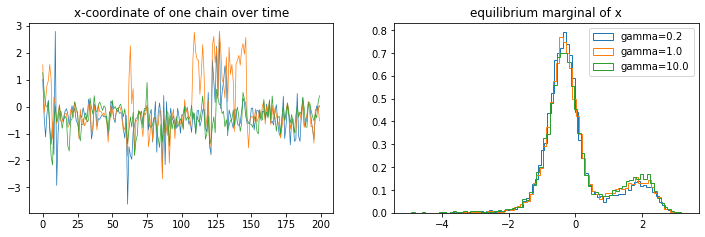

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for gamma in [0.2, 1.0, 10.0]:
    s, tr = ex.simulate_model(None, x, force=F_true, gamma=gamma, n_steps=10_000, n_chains=50)
    print(f'gamma={gamma:5}: small-basin fraction {ex.mb_small_basin_fraction(s, info):.3f}')
    ax[0].plot(tr[:, 0, 0], lw=0.7, label=f'gamma={gamma}')
    ax[1].hist(s[:, 0].numpy(), 80, density=True, histtype='step', label=f'gamma={gamma}')
ax[0].set_title('x-coordinate of one chain over time'); ax[1].set_title('equilibrium marginal of x'); ax[1].legend()

## 5. Conservative (`EnergyNet`) vs. direct score (`ScoreNet`)
A force field must be curl-free: `∂s_y/∂x − ∂s_x/∂y = 0`. The gradient of a scalar network satisfies this
by construction; a vector-valued network does not. (App. C.1 found score networks unstable in simulation.)
We train a small `ScoreNet` quickly for this comparison.

In [7]:
energy_model = ex.get_model('mb_diffusion')
from scoremd.train import train
torch.manual_seed(0)
score_model = models.ScoreNet(2, 92, 3)
_ = train(score_model, x, steps=3000, lr=1e-3, log_every=1000); score_model.eval()

def curl(model, pts, t=1e-5):
    pts = pts.clone().requires_grad_(True)
    tt = torch.full((len(pts),), t)
    with torch.enable_grad():
        if model.conservative:   # score = grad of the energy, kept differentiable w.r.t. pts
            s = torch.autograd.grad(model.log_p(pts, tt).sum(), pts, create_graph=True)[0]
        else:
            s = model.score(pts, tt)
        dsx = torch.autograd.grad(s[:, 0].sum(), pts, retain_graph=True)[0]
        dsy = torch.autograd.grad(s[:, 1].sum(), pts)[0]
    return (dsy[:, 0] - dsx[:, 1]).detach()

pts = x[:2000]
for name, m in [('EnergyNet', energy_model), ('ScoreNet', score_model)]:
    print(f'{name:10s}: mean |curl| at data points = {curl(m, pts).abs().mean():.2e}')

loaded mb_diffusion_seed0.pt
step   1000 | dsm 0.5498 | 6s
step   2000 | dsm 0.4386 | 11s
step   3000 | dsm 0.4243 | 17s
EnergyNet : mean |curl| at data points = 3.39e-16
ScoreNet  : mean |curl| at data points = 5.55e-02


## Exercises
1. Simulate with `score_model` (`ex.simulate_model(score_model, x)`) and with `energy_model` — compare the free energies.
   (Part 3 looks at the energy model in detail.)
2. Why is a non-zero curl a problem for MD? (Hint: energy conservation / detailed balance.)